# 01 - Data Understanding & Exploratory Data Analysis

**Project:** MedPredict - Explainable Machine Learning for Cardiovascular Disease Risk Prediction
**Dataset:** UCI Heart Disease - Cleveland Clinic Foundation (`processed.cleveland.data`)

**Goals of this notebook**

1. Understand what each variable means and how it is coded.
2. Check data quality (missing values, duplicates, impossible values, outliers).
3. Study the target variable and its class balance.
4. Study how each feature relates to the presence of heart disease.
5. Turn what we learn into concrete preprocessing and evaluation decisions.

> This is an *exploratory* analysis of a small, historical dataset. Associations found here describe the model's training data - they are not clinical claims.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # make `src` importable
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.preprocessing import (
    load_data, NUMERIC, BINARY, NOMINAL, FEATURES,
    FEATURE_DESCRIPTIONS, VALUE_LABELS, RESULTS_DIR,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
RESULTS_DIR.mkdir(exist_ok=True)
PAL = {0: "#4c72b0", 1: "#c44e52"}                   # 0 = no disease, 1 = disease

def save(fig, name):
    fig.savefig(RESULTS_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")

df = load_data()
print(f"Rows: {df.shape[0]}   Columns: {df.shape[1]}")
df.head()

Rows: 303   Columns: 15


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


## 1. Dataset overview

The file has 303 patients, 13 input attributes and one diagnosis column (`num`, 0-4). Following the standard practice for this dataset, we collapse `num` into a **binary target**: `0` = no disease, `1` = disease present (`num` > 0).

In [2]:
kind = {**{c: "numeric" for c in NUMERIC[:-1]}, "ca": "ordinal count (0-3)",
        **{c: "binary" for c in BINARY}, **{c: "categorical" for c in NOMINAL}}
dictionary = pd.DataFrame({
    "description": pd.Series(FEATURE_DESCRIPTIONS),
    "type": pd.Series(kind),
    "coding": pd.Series({c: ", ".join(f"{k}={v}" for k, v in VALUE_LABELS[c].items()) for c in VALUE_LABELS}),
}).loc[FEATURES].fillna("")
dictionary

,description,type,coding
age,Age (years),numeric,
trestbps,Resting blood pressure (mm Hg),numeric,
chol,Serum cholesterol (mg/dl),numeric,
thalach,Max heart rate achieved,numeric,
oldpeak,ST depression (exercise vs rest),numeric,
ca,Major vessels coloured by fluoroscopy (0-3),ordinal count (0-3),
sex,Sex,binary,"0=Female, 1=Male"
fbs,Fasting blood sugar > 120 mg/dl,binary,"0=<= 120 mg/dl, 1=> 120 mg/dl"
exang,Exercise-induced angina,binary,"0=No, 1=Yes"
cp,Chest pain type,categorical,"1=Typical angina, 2=Atypical angina, 3=Non-ang..."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
 14  target    303 non-null    int64  
dtypes: float64(13), int64(2)
memory usage: 35.6 KB


In [4]:
df[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0


## 2. Data quality
### 2.1 Missing values

In [5]:
missing = df[FEATURES].isna().sum()
print("Missing values per column (only columns with gaps):")
print(missing[missing > 0].to_string())
print(f"\nRows with at least one missing value: {df[FEATURES].isna().any(axis=1).sum()} "
      f"of {len(df)} ({df[FEATURES].isna().any(axis=1).mean():.1%})")
df[df[FEATURES].isna().any(axis=1)][["age", "sex", "ca", "thal", "num", "target"]]

Missing values per column (only columns with gaps):
ca      4
thal    2

Rows with at least one missing value: 6 of 303 (2.0%)


,age,sex,ca,thal,num,target
87,53.0,0.0,0.0,NaN,0,0
166,52.0,1.0,NaN,3.0,0,0
192,43.0,1.0,NaN,7.0,1,1
266,52.0,1.0,0.0,NaN,2,1
287,58.0,1.0,NaN,7.0,0,0
302,38.0,1.0,NaN,3.0,0,0


### 2.2 Duplicates, impossible values and rare categories

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print()
print("Range of numeric variables (min / max):")
print(df[NUMERIC].agg(["min", "max"]).T.to_string())
print()
for c in NOMINAL + BINARY:
    print(f"{c:<8}", df[c].value_counts(dropna=False).sort_index().to_dict())

Duplicate rows: 0

Range of numeric variables (min / max):
            min    max
age        29.0   77.0
trestbps   94.0  200.0
chol      126.0  564.0
thalach    71.0  202.0
oldpeak     0.0    6.2
ca          0.0    3.0

cp       {1.0: 23, 2.0: 50, 3.0: 86, 4.0: 144}
restecg  {0.0: 151, 1.0: 4, 2.0: 148}
slope    {1.0: 142, 2.0: 140, 3.0: 21}
thal     {3.0: 166, 6.0: 18, 7.0: 117, nan: 2}
sex      {0.0: 97, 1.0: 206}
fbs      {0.0: 258, 1.0: 45}
exang    {0.0: 204, 1.0: 99}


**Observations - data quality**

* **No duplicate rows**, and every numeric value lies in a physiologically plausible range (e.g. resting blood pressure 94-200 mm Hg, cholesterol 126-564 mg/dl, max heart rate 71-202 bpm). We found no evidence of coding errors.
* **Only 6 missing values in 6 different rows (2.0 % of patients)**: 4 in `ca` and 2 in `thal`. They are too few to justify dropping patients from a 303-row dataset, and the affected rows are a mix of disease and no-disease cases, so we will impute them **inside the modelling pipeline** (see notebook 02) rather than with `dropna()`.
* **Some categories are very small**: `restecg = 1` has only 4 patients, `thal = 6` has 18 and `slope = 3` has 21. Conclusions about these levels are fragile.

## 3. Target variable

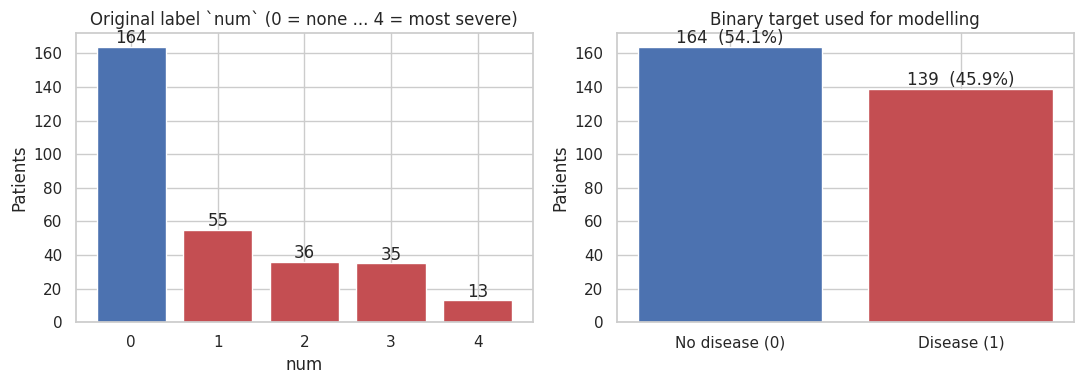

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

orig = df["num"].value_counts().sort_index()
axes[0].bar(orig.index.astype(str), orig.values, color=["#4c72b0"] + ["#c44e52"] * 4)
for i, v in enumerate(orig.values):
    axes[0].text(i, v + 2, str(v), ha="center")
axes[0].set(title="Original label `num` (0 = none ... 4 = most severe)", xlabel="num", ylabel="Patients")

binary = df["target"].value_counts().sort_index()
axes[1].bar(["No disease (0)", "Disease (1)"], binary.values, color=[PAL[0], PAL[1]])
for i, v in enumerate(binary.values):
    axes[1].text(i, v + 2, f"{v}  ({v / len(df):.1%})", ha="center")
axes[1].set(title="Binary target used for modelling", ylabel="Patients")

fig.tight_layout(); save(fig, "target_distribution"); plt.show()

**Observations - target**

* 164 patients (54.1 %) have no disease and 139 (45.9 %) have disease: the classes are **nearly balanced**. We do not need resampling, but we will still report precision, recall, F1 and ROC-AUC because in a medical setting a *missed* case (false negative) and a *false alarm* (false positive) have very different costs, and accuracy hides that difference.
* The original 1-4 severity levels are small (55 / 36 / 35 / 13 patients). Predicting severity would be unreliable, which is why we model **presence vs absence**.

## 4. Numeric features vs. the target

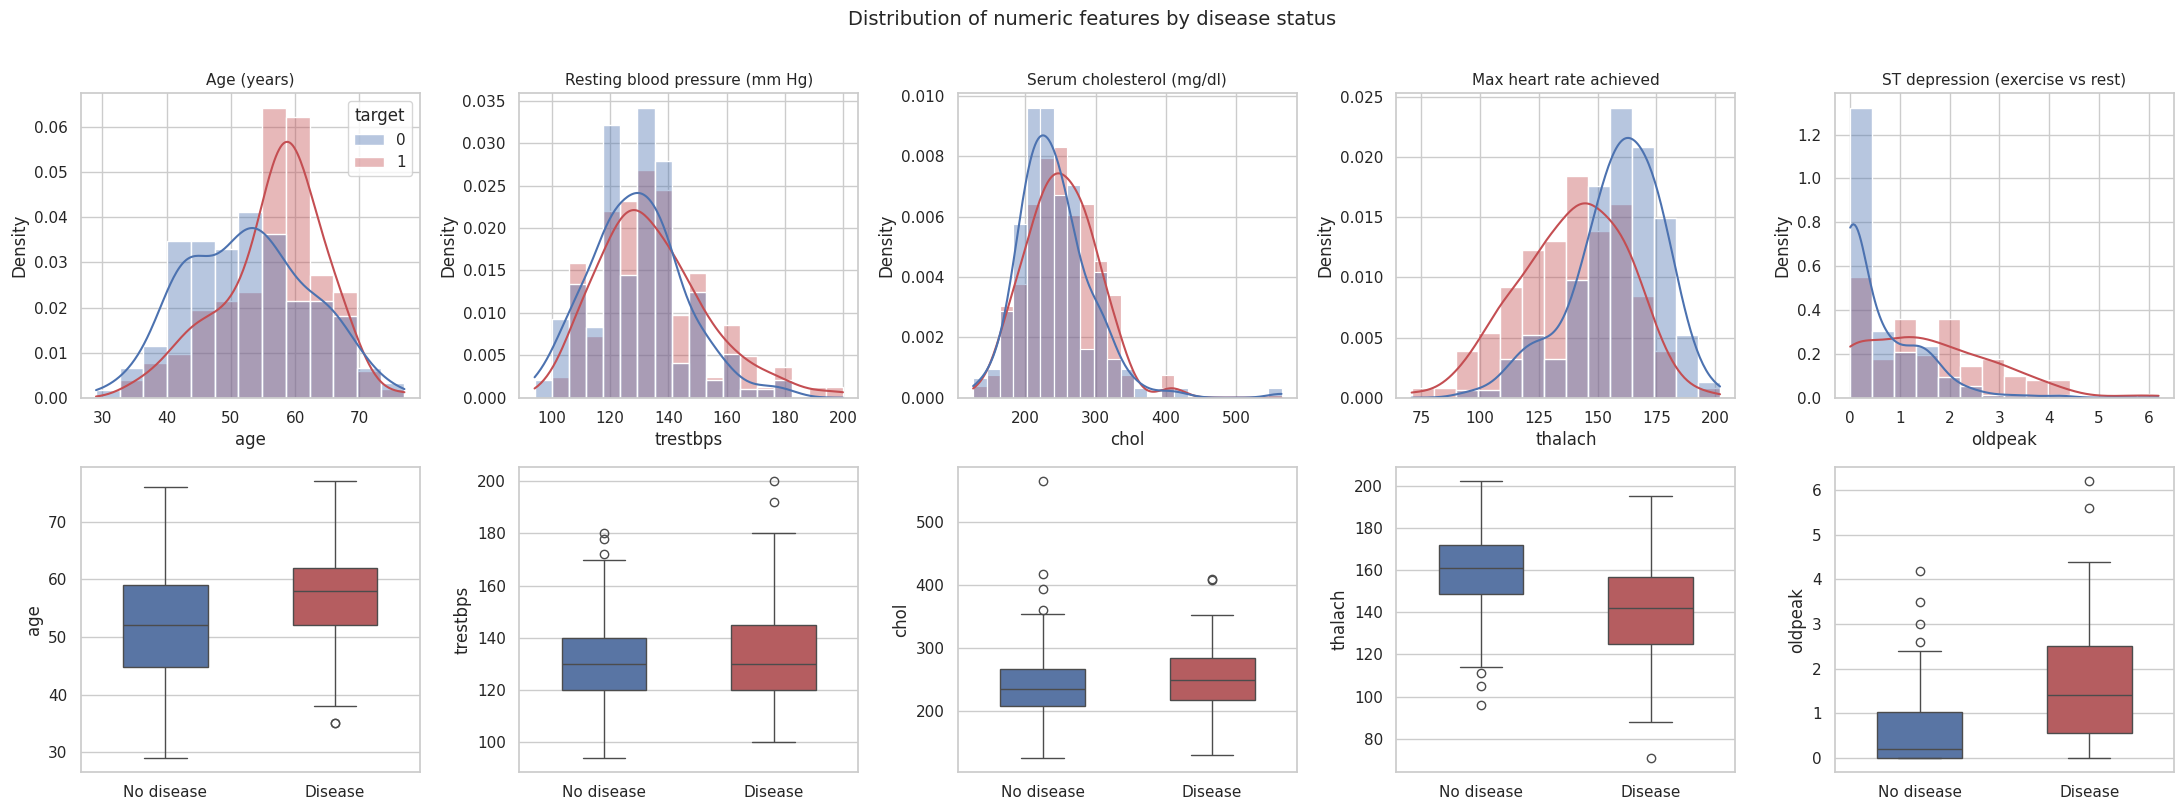

In [8]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for j, c in enumerate(num_cols):
    sns.histplot(data=df, x=c, hue="target", palette=PAL, kde=True, stat="density",
                 common_norm=False, alpha=0.4, ax=axes[0, j], legend=(j == 0))
    axes[0, j].set_title(FEATURE_DESCRIPTIONS[c], fontsize=11)
    sns.boxplot(data=df, x="target", y=c, hue="target", palette=PAL, legend=False, ax=axes[1, j], width=0.5)
    axes[1, j].set_xticklabels(["No disease", "Disease"])
    axes[1, j].set_xlabel("")
fig.suptitle("Distribution of numeric features by disease status", y=1.01, fontsize=14)
fig.tight_layout(); save(fig, "numeric_distributions"); plt.show()

In [9]:
rows = []
for c in num_cols:
    a, b = df.loc[df.target == 0, c], df.loc[df.target == 1, c]
    rows.append({
        "feature": c,
        "mean (no disease)": a.mean(), "mean (disease)": b.mean(),
        "median (no disease)": a.median(), "median (disease)": b.median(),
        "skewness": df[c].skew(),
        "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue,
    })
num_tests = pd.DataFrame(rows).set_index("feature")
num_tests.round(3).style.format({"Mann-Whitney p": "{:.2e}"})

,mean (no disease),mean (disease),median (no disease),median (disease),skewness,Mann-Whitney p
feature,,,,,,
age,52.585000,56.626000,52.000000,58.000000,-0.209000,0.00e+00
trestbps,129.250000,134.568000,130.000000,130.000000,0.706000,2.60e-02
chol,242.640000,251.475000,234.500000,249.000000,1.136000,3.50e-02
thalach,158.378000,139.259000,161.000000,142.000000,-0.537000,0.00e+00
oldpeak,0.587000,1.574000,0.200000,1.400000,1.270000,0.00e+00


In [10]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
pd.DataFrame({"IQR outliers": outliers, "max value": df[num_cols].max()})

,IQR outliers,max value
age,0,77.0
trestbps,9,200.0
chol,5,564.0
thalach,1,202.0
oldpeak,5,6.2


**Observations - numeric features**

* **`thalach` (max heart rate) and `oldpeak` (ST depression) separate the classes best.** Patients with disease reach a much lower maximum heart rate (mean 139 vs 158 bpm) and show larger ST depression (mean 1.6 vs 0.6). Both differences are highly significant (Mann-Whitney p < 1e-12).
* **`age` is moderately associated** (mean 56.6 vs 52.6 years, p < 1e-4).
* **`trestbps` and `chol` are only weakly associated** (p = 0.026 and 0.035; means differ by ~5 mm Hg and ~9 mg/dl). With five tests run, these would not survive a Bonferroni correction (threshold 0.01), so we treat them as weak signals.
* **Skew and outliers:** `oldpeak` (skew 1.27) and `chol` (1.14) are right-skewed; there are a handful of IQR outliers (9 in `trestbps`, 5 in `chol`, 5 in `oldpeak`, 1 in `thalach`), e.g. cholesterol up to 564 mg/dl and ST depression up to 6.2. These are plausible measurements, not errors, so we **keep them**. Tree-based models are insensitive to them; for logistic regression they may have some leverage, which is one more reason to compare models.

## 5. Categorical features vs. the target

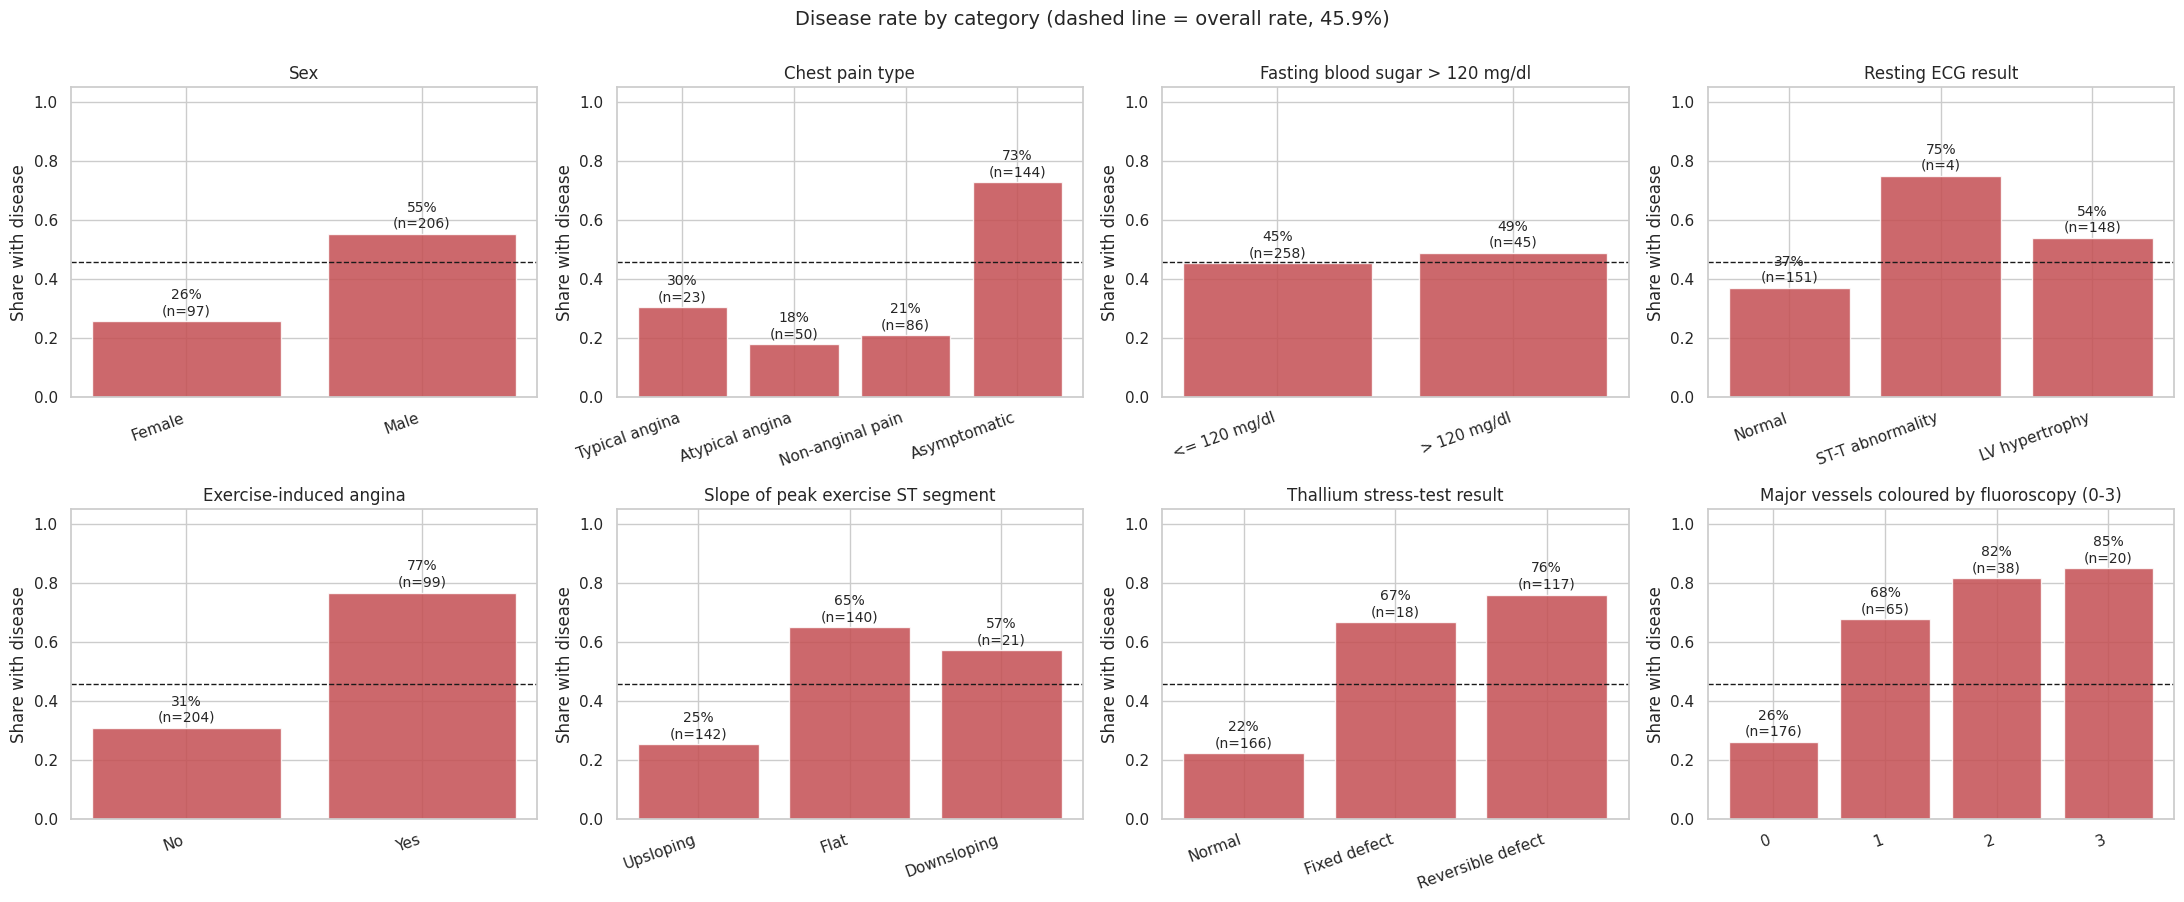

In [11]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal", "ca"]
overall = df["target"].mean()

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, c in zip(axes.ravel(), cat_cols):
    s = df[[c, "target"]].dropna()
    g = s.groupby(c)["target"].agg(["mean", "count"])
    labels = [VALUE_LABELS[c].get(int(k), str(int(k))) if c in VALUE_LABELS else str(int(k)) for k in g.index]
    bars = ax.bar(range(len(g)), g["mean"], color="#c44e52", alpha=0.85)
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, m + 0.02, f"{m:.0%}\n(n={n})", ha="center", fontsize=10)
    ax.axhline(overall, color="k", ls="--", lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set(ylim=(0, 1.05), title=FEATURE_DESCRIPTIONS[c], ylabel="Share with disease")
fig.suptitle(f"Disease rate by category (dashed line = overall rate, {overall:.1%})", y=1.0, fontsize=14)
fig.tight_layout(); save(fig, "categorical_vs_target"); plt.show()

In [12]:
rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df["target"])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum()
    rows.append({"feature": c, "chi2": chi2, "p-value": p,
                 "Cramer's V": np.sqrt(chi2 / (n * (min(ct.shape) - 1))),
                 "cells with expected count < 5": int((expected < 5).sum())})
cat_tests = pd.DataFrame(rows).set_index("feature").sort_values("Cramer's V", ascending=False)
cat_tests.style.format({"chi2": "{:.1f}", "p-value": "{:.1e}", "Cramer's V": "{:.2f}"})

,chi2,p-value,Cramer's V,cells with expected count < 5
feature,,,,
thal,83.3,8.2e-19,0.53,0
cp,81.8,1.3e-17,0.52,0
ca,71.8,1.7e-15,0.49,0
exang,54.7,1.4e-13,0.42,0
slope,45.8,1.1e-10,0.39,0
sex,22.0,2.7e-06,0.27,0
restecg,10.1,6.6e-03,0.18,2
fbs,0.1,7.8e-01,0.02,0


**Observations - categorical features**

* **`thal` (thallium test) and `ca` (number of coloured vessels) are the strongest categorical signals.** Disease prevalence is 22 % for a normal thallium result vs 67 % (fixed defect) and 76 % (reversible defect); for `ca` it climbs steadily from 26 % (0 vessels) to 68 %, 82 % and 85 % (1, 2, 3 vessels). This monotonic pattern supports treating `ca` as an ordered numeric variable.
* **Exercise-induced angina (`exang`)**: 77 % disease with angina vs 31 % without.
* **Chest-pain type (`cp`)**: patients labelled *asymptomatic* (type 4, n = 144) have the highest disease rate (73 %) versus 18-30 % for the three pain types. This looks counter-intuitive, but it is a well-known feature of this dataset (the cohort consists of patients referred for angiography) - it is an association in *this sample*, not a clinical rule.
* **`slope`**: flat (65 %) and downsloping (57 %) ST segments carry much higher risk than upsloping (25 %).
* **`sex`**: 55 % of men vs 26 % of women have the disease, but the sample is **68 % male (206 vs 97)**, so the model will have seen far fewer women.
* **`fbs` (fasting blood sugar) is essentially unrelated** to the target (45 % vs 49 %, p = 0.78).
* **`restecg`**: only 4 patients have an ST-T abnormality, so the 75 % figure for that group is unreliable; the chi-square test also has cells with expected counts below 5 (see table), so its p-value should be read with caution.

## 6. Correlations

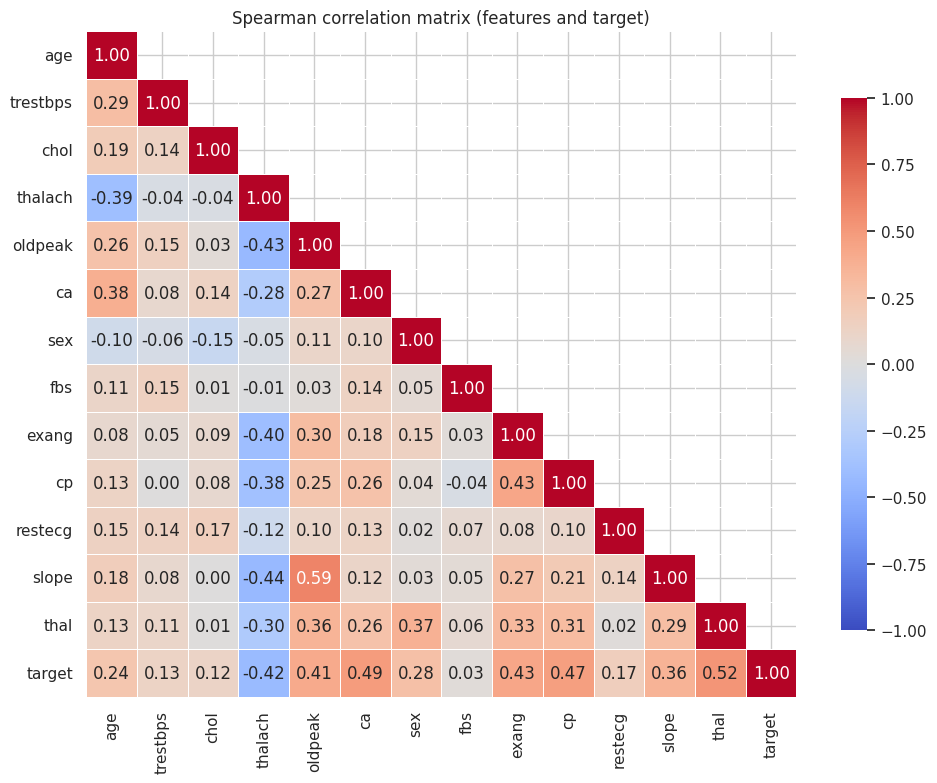

Correlation with target (sorted):
thal        0.52
ca          0.49
cp          0.47
exang       0.43
oldpeak     0.41
slope       0.36
sex         0.28
age         0.24
restecg     0.17
trestbps    0.13
chol        0.12
fbs         0.03
thalach    -0.42

Strongest feature-feature correlations:
slope    oldpeak    0.59
         thalach   -0.44
cp       exang      0.43
oldpeak  thalach   -0.43
exang    thalach   -0.40


In [13]:
corr = df[FEATURES + ["target"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation matrix (features and target)")
fig.tight_layout(); save(fig, "correlation_heatmap"); plt.show()

print("Correlation with target (sorted):")
print(corr["target"].drop("target").sort_values(ascending=False).round(2).to_string())

pairs = corr.where(~mask & (np.abs(corr) < 1)).drop(index="target", columns="target").stack()
print("\nStrongest feature-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(2).to_string())

**Observations - correlations**

* `thal` (0.52), `ca` (0.49), `cp` (0.47), `exang` (0.43) and `oldpeak` (0.41) show the strongest positive correlations with the target, and `thalach` the strongest negative one (-0.42). This agrees with the univariate tests above.
* No pair of features is strongly collinear: the largest feature-feature correlation is 0.59 (`slope` vs `oldpeak`), followed by values around 0.4-0.44, so multicollinearity is not a serious concern for logistic regression here.
* These are *marginal* associations. A model can use interactions between features that a correlation matrix cannot show, which is one reason to test tree-based models next to the logistic-regression baseline.

## 7. Age and sex

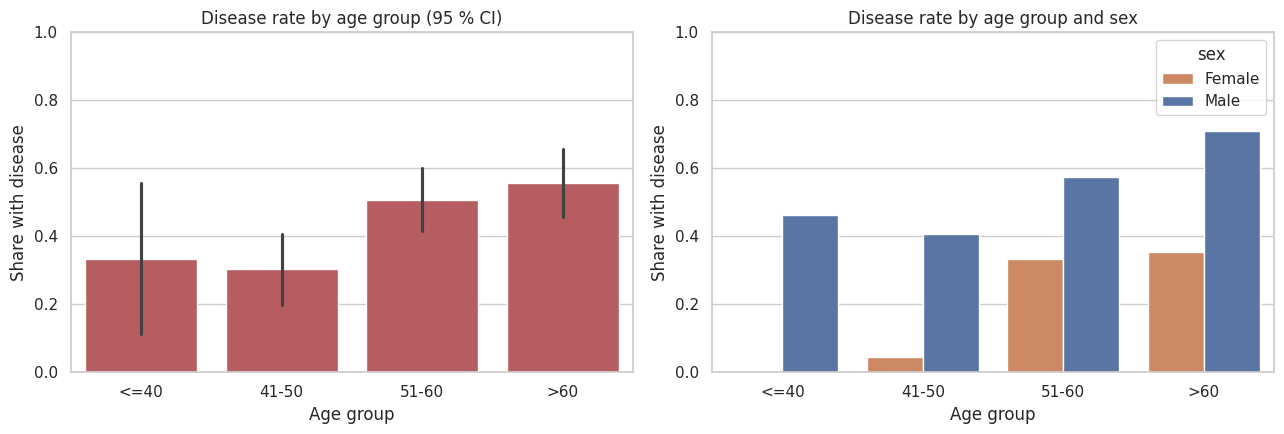

age_group   <=40  41-50   51-60    >60
mean        0.33    0.3    0.51   0.56
count      18.00   76.0  130.00  79.00


In [14]:
bins = [28, 40, 50, 60, 80]
labels = ["<=40", "41-50", "51-60", ">60"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)
by = df.groupby(["age_group", "sex"], observed=True)["target"].agg(["mean", "count"]).reset_index()
by["sex"] = by["sex"].map(VALUE_LABELS["sex"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x="age_group", y="target", color="#c44e52", errorbar=("ci", 95), ax=axes[0])
axes[0].set(title="Disease rate by age group (95 % CI)", xlabel="Age group", ylabel="Share with disease", ylim=(0, 1))
sns.barplot(data=by, x="age_group", y="mean", hue="sex", ax=axes[1], palette=["#dd8452", "#4c72b0"])
axes[1].set(title="Disease rate by age group and sex", xlabel="Age group", ylabel="Share with disease", ylim=(0, 1))
fig.tight_layout(); save(fig, "age_sex"); plt.show()

print(df.groupby("age_group", observed=True)["target"].agg(["mean", "count"]).round(2).T.to_string())
df = df.drop(columns="age_group")

**Observations - age and sex**

* The disease rate is roughly 30-33 % for patients aged 50 or younger and rises to 51 % (51-60) and 56 % (over 60). The youngest group has only 18 patients, hence the wide interval.
* Men have a higher disease rate than women in every age group (e.g. 57 % vs 33 % at 51-60, 71 % vs 35 % above 60), but women are few per age group (only 5 women aged 40 or younger, none with disease), so we would not draw fine-grained conclusions about sex differences from this data.

## 8. Summary and decisions for the next stages

| Finding | Decision |
|---|---|
| 6 missing values (`ca`: 4, `thal`: 2), 2 % of rows | Impute inside the pipeline (median for numeric, mode for categorical); no `dropna()` |
| Classes nearly balanced (54 % / 46 %) | Stratified split; report precision, recall, F1, ROC-AUC (not just accuracy) |
| Numeric features on different scales; skewed `oldpeak`, `chol` | Standardise numeric features (needed by logistic regression); keep outliers (plausible values) |
| `cp`, `restecg`, `slope`, `thal` are unordered codes | One-hot encode |
| `ca` is a 0-3 ordered count with a monotonic effect | Keep as numeric |
| `sex`, `fbs`, `exang` are already 0/1 | Pass through (impute only) |
| Small dataset (303 rows), some rare categories | Nested cross-validation for model comparison; bootstrap confidence intervals on the test set |
| 68 % of patients are male; single hospital | Document as a limitation (no claims about generalisation) |
| `fbs`, `chol`, `trestbps` are weak signals | Keep all 13 features (the models will weigh them); check importance afterwards |

**Next:** `02_preprocessing.ipynb` implements these decisions as a leakage-free scikit-learn pipeline.